In [1]:
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
from astropy.constants import G

import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import (NFWPotential, TwoPowerSphericalPotential, AnySphericalPotential,evaluateDensities)
from colossus.cosmology import cosmology
from colossus.halo import concentration, profile_nfw
from scipy.optimize import minimize, fsolve
from math import pi
from galpy.orbit import Orbit       #tri des données euclid
import sys
import pandas as pd
import time
from astropy.constants import G
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, vcirc, FDMDynamicalFrictionForce as FDM_DF
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D


cosmology.setCosmology('planck15')

In [2]:
#Core profile

#same but with Core profile

def zeta(z, Omega_m):
    return (18 * np.pi**2 + 82 * (Omega_m - 1) - 39 * (Omega_m - 1)**2) / Omega_m

def r_c(z, M_h, m_22, Omega_m):
    return (1.6 / np.sqrt(1 + z)) * (zeta(z, Omega_m) / zeta(0, Omega_m0))**(-1/6) * (M_h / 1e9)**(-1/3) * m_22**-1

def rho2_z(r_c, m_22, z):
    return 1.9 * (10 * m_22)**-2 * r_c**-4 * 1e9 / ((1 + z)**3)

zgo = 0
cosmo = cosmology.setCosmology('planck18')
Omega_m0 = cosmo.Om(zgo)

def FDMhalo(m22, M):

    Mh=M*0.704
    rc1 = r_c(zgo, M, m22, Omega_m0)
    rhoFDM = rho2_z(rc1, m22, zgo)
    AmpFDM = rhoFDM * 4 * pi * rc1**3

    rc2 = r_c(zgo, M, m22/10, Omega_m0)
    rhoFDM2 = rho2_z(rc2, m22/10, zgo)
    AmpFDM2 = rhoFDM2 * 4 * pi * rc2**3
    

    C2 = concentration.concentration(M*0.704, 'vir', zgo, model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=M*0.704, c=C2, z=zgo, mdef='vir')
    rs = p_nfw.par['rs'] / 0.704
    A=np.log(1+C2)-C2/(1+C2)

    DMhalo2 = NFWPotential(amp=M/A * u.Msun, a=rs*u.kpc)
    r_vals = np.logspace(np.log10(0.001), np.log10(1000), 200)
    FDMhalo_soliton = AnySphericalPotential(dens=lambda r: rhoFDM / ((1 + 0.091 * (r / rc1)**2)**8))

    def cost(params):
        psi, gamma, eta = params
        if psi <= 0 or gamma <= 0 or eta <= 0:
            return np.inf

        def equation(alpha):
            FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
            dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc)
            dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc)
            return (dens_FDM3 - dens_CDM) / dens_CDM

        try:
            alpha_sol = fsolve(equation, 10)[0]
        except:
            return np.inf

        FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha_sol**3) * u.Msun, a=alpha_sol * rc2 * u.kpc, alpha=0, beta=3)
        CoreFDM = TwoPowerSphericalPotential(amp=AmpFDM * (gamma**3) * u.Msun, a=gamma * rc1 * u.kpc, alpha=0, beta=eta)
        total_ref = np.array([evaluateDensities(FDMhalo_soliton, r, 0) + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        total_test = np.array([evaluateDensities(CoreFDM, r * u.kpc, 0 * u.kpc) * 1e9 + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        return np.mean((np.log10(total_ref + 1e-30) - np.log10(total_test + 1e-30))**2)

    result = minimize(cost, x0=[0.5, 12.0, 20.0], bounds=[(0.0001, 0.7 * (1e10 / M) * (10 / m22)), (1, 10), (3, 10)], method='L-BFGS-B')
    psi_opt, gamma_opt, eta_opt = result.x

    def equation(alpha):
        FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
        dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc) * 1e9
        dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc) * 1e9
        return (dens_FDM3 - dens_CDM) / dens_CDM

    alpha_final = fsolve(equation, 10)[0]
    FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha_final**3) * u.Msun, a=alpha_final * rc2 * u.kpc, alpha=0, beta=3)
    CoreFDM = TwoPowerSphericalPotential(amp=(gamma_opt**3) * AmpFDM * u.Msun, a=gamma_opt * rc1 * u.kpc, alpha=0, beta=eta_opt)
    return CoreFDM + FDMhalo3


In [3]:
#parameters
Ms=2.39e7
rhm=0.01
RGC=np.array([0.43,0.24])*(2/np.sqrt(3))
MGC=np.array([3.63e5,1.32e5])
ts=np.linspace(0,10,2001)*u.Gyr
#m22_values=np.logspace(np.log10(1),np.log10(3),10)
m22_values=np.array([1.69,2.87])
    
#masse stellaire
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
DMhalomass=model.mean_log_halo_mass(logMs)
M=10**DMhalomass

#calcul du potentiel de la galaxie
Mh=M*0.704
c=concentration.concentration(Mh,'vir',0,model='prada12')
p_nfw=profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
rs=p_nfw.par['rs']/0.704
A=np.log(1+c)-c/(1+c)
NFW_pot=NFWPotential(amp=M/A*u.Msun,a=rs*u.kpc)

#calcul des orbites
e=0.5
os=[[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC]
t=ts.value
masses=(m22_values*1e-22)*u.eV
def run(i):
    o=os[i]
    mgc=MGC[i]
    gc_results=[]
    for j,m in enumerate(masses):
        orb=Orbit(o)
        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=m)
        #cdf= CDFF(GMs=mgc*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
        gc_results.append({"m22":m22_values[j],"r":orb.r(ts)})
    return gc_results

res=Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))
all_results=np.array(res,dtype=object)
print(all_results.shape)

(2, 2)


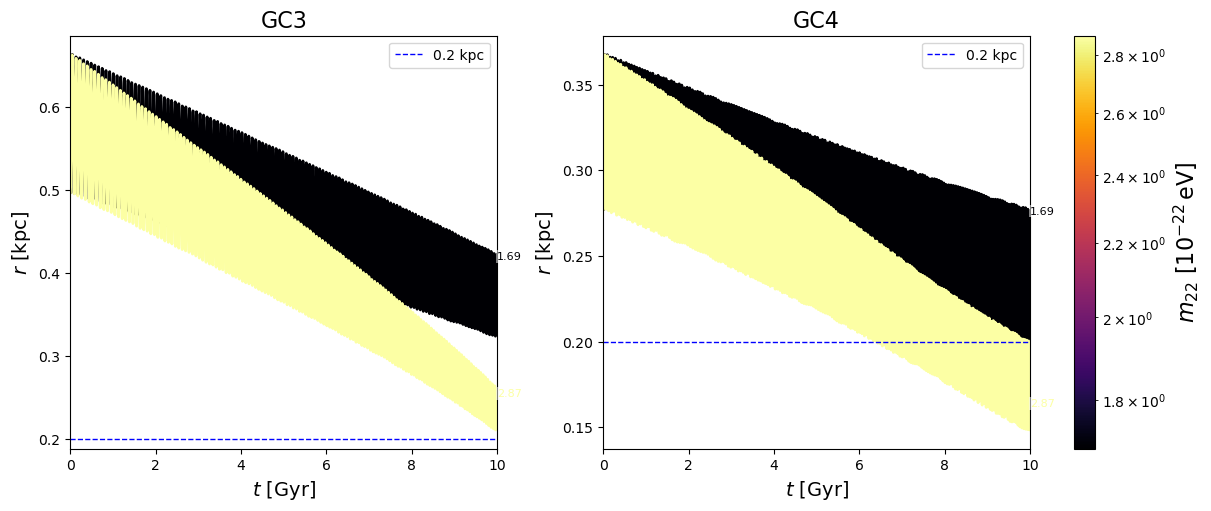

In [4]:
#plot
#%matplotlib widget
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(12, 5), constrained_layout=True)
cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())
for i, ax in enumerate(axes):
    for res in all_results[i]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])), lw=2)
        ax.text(t[-1],res["r"][-1],f'{res["m22"]:.2f}', color=cmap(norm(res["m22"])),fontsize=8,ha='left',va='center',bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

    ax.axhline(0.2, color='blue', linestyle='--', lw=1,label="0.2 kpc")
    ax.set_title(f'GC{i+3}', fontsize=16)
    ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$', fontsize=14)
    ax.set_ylabel(r'$r\ \mathrm{[kpc]}$', fontsize=14)
    ax.set_xlim(0, 10)
    ax.legend()

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=16)
cbar.ax.tick_params(labelsize=12)
plt.savefig("E1.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
#parameters
Ms=2.39e7
rhm=0.01
RGC=np.array([0.43,0.24])*(2/np.sqrt(3))
MGC=np.array([3.63e5,1.32e5])
ts=np.linspace(0,10,1001)*u.Gyr
#m22_values=np.logspace(np.log10(1),np.log10(30),10)
m22_values=np.array([1.5])
#m22_values=np.linspace(1,21,10)

#masse stellaire
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
DMhalomass=model.mean_log_halo_mass(logMs)
M=10**DMhalomass

#calcul du potentiel de la galaxie
Mh=M*0.704
c=concentration.concentration(Mh,'vir',0,model='prada12')
p_nfw=profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
rs=p_nfw.par['rs']/0.704
A=np.log(1+c)-c/(1+c)
NFW_pot=NFWPotential(amp=M/A*u.Msun,a=rs*u.kpc)

#calcul des orbites
e=0.5
a=np.sqrt(1+e)
os=[[r*u.kpc,0*u.km/u.s,a*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC]
t=ts.value
masses=(m22_values*1e-22)*u.eV

def run(i):
    cosmology.setCosmology('planck15')
    o=os[i]
    mgc=MGC[i]
    gc_results=[]
    gc_results2=[]
    for j,m in enumerate(masses):
        m22=m22_values[j]
        pot=FDMhalo(m22,M)
        o2=[RGC[i]*u.kpc,0*u.km/u.s,a*vcirc(pot,RGC[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]
        
        orb=Orbit(o)
        orb2=Orbit(o2)

        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=m)
        fdm=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=pot,m=m)

        orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
        orb2.integrate(ts,pot+fdm,method='dop853_c')

        gc_results.append({"m22":m22,"r":orb.r(ts)})
        gc_results2.append({"m22":m22,"r":orb2.r(ts)})
    return gc_results2   #,gc_results2

res=Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))
all_results=np.array(res,dtype=object)

print(all_results.shape)

(2, 1)


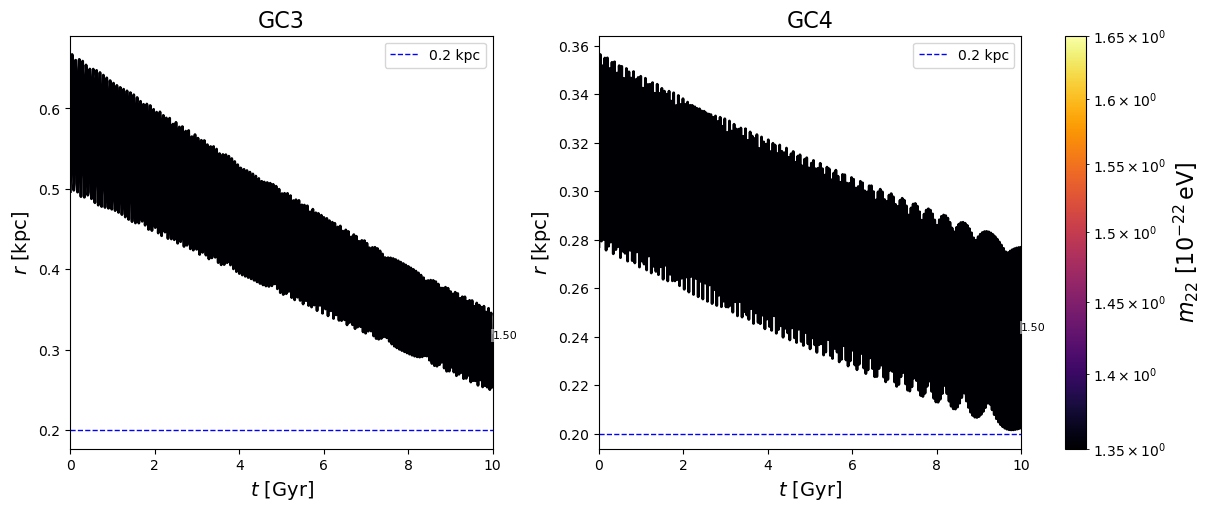

In [9]:
#plot
#%matplotlib widget
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(12, 5), constrained_layout=True)
cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())
for i, ax in enumerate(axes):
    for res in all_results[i]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])), lw=2)
        ax.text(t[-1],res["r"][-1],f'{res["m22"]:.2f}', color=cmap(norm(res["m22"])),fontsize=8,ha='left',va='center',bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

    ax.axhline(0.2, color='blue', linestyle='--', lw=1,label="0.2 kpc")
    ax.set_title(f'GC{i+3}', fontsize=16)
    ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$', fontsize=14)
    ax.set_ylabel(r'$r\ \mathrm{[kpc]}$', fontsize=14)
    ax.set_xlim(0, 10)
    ax.legend()

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=16)
cbar.ax.tick_params(labelsize=12)
plt.savefig("E1.png", dpi=300, bbox_inches="tight")
plt.show()

TypeError: string indices must be integers, not 'str'

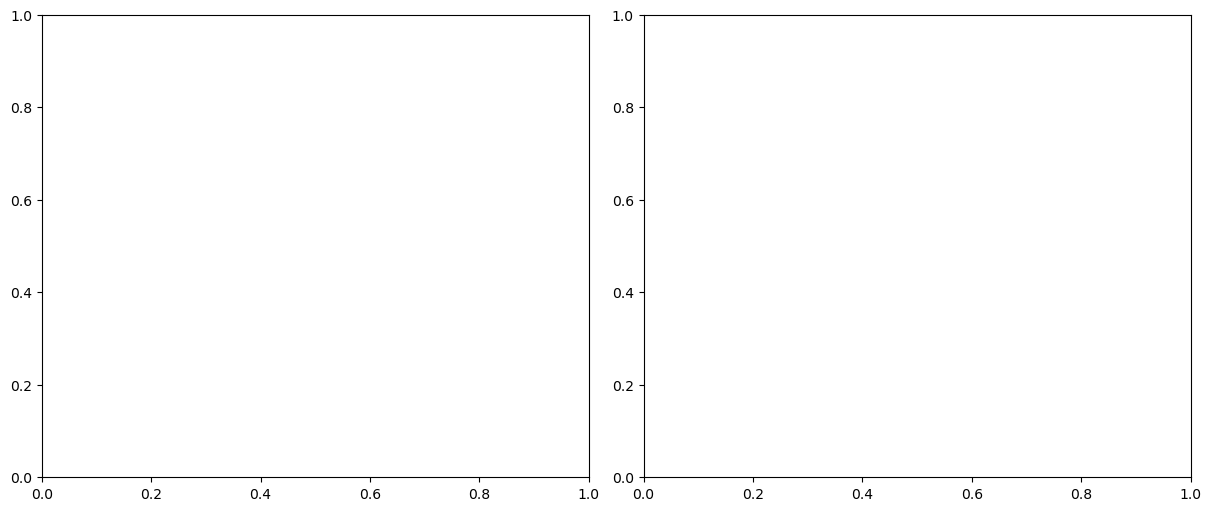

In [7]:
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(12, 5), constrained_layout=True)
cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())

for i, ax in enumerate(axes):
    for model_idx in range(2):
        results_model = all_results[i, model_idx]
        for res in results_model:
            color = cmap(norm(res["m22"]))
            linestyle = "-" if model_idx == 0 else "--"
            r = res["r"].to_value(u.kpc) if hasattr(res["r"], "unit") else res["r"]
            ax.plot(t, r, color=color, lw=2, ls=linestyle, alpha=0.9)
            ax.text(t[-1],r[-1],f'{res["m22"]:.2f}',color=color,fontsize=8,ha='left',va='center',bbox=dict(facecolor='white',alpha=0.5,edgecolor='none',pad=1))
    ax.axhline(0.2, color='blue', linestyle='--', lw=1)
    ax.set_title(f'GC{i+3}', fontsize=16)
    ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$', fontsize=14)
    ax.set_ylabel(r'$r\ \mathrm{[kpc]}$', fontsize=14)
    ax.set_xlim(0,10)

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=16)
cbar.ax.tick_params(labelsize=12)

legend_elements = [Line2D([0],[0],color='black',lw=2,ls='-',label='NFW profile'),Line2D([0],[0],color='black',lw=2,ls='--',label='Core profile')]
axes[0].legend(handles=legend_elements)

plt.savefig("R2D.png", dpi=300, bbox_inches="tight")
plt.show()